Using Colab cache for faster access to the 'bostonhoustingmlnd' dataset.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 489 entries, 0 to 488
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   RM       489 non-null    float64
 1   LSTAT    489 non-null    float64
 2   PTRATIO  489 non-null    float64
 3   MEDV     489 non-null    float64
dtypes: float64(4)
memory usage: 15.4 KB


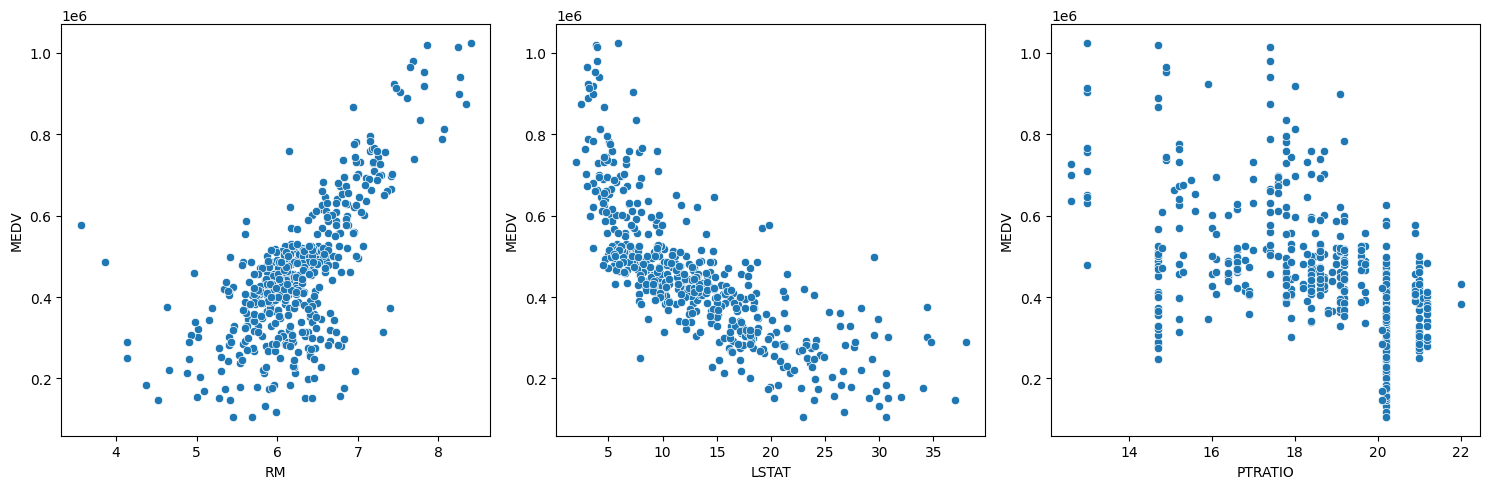

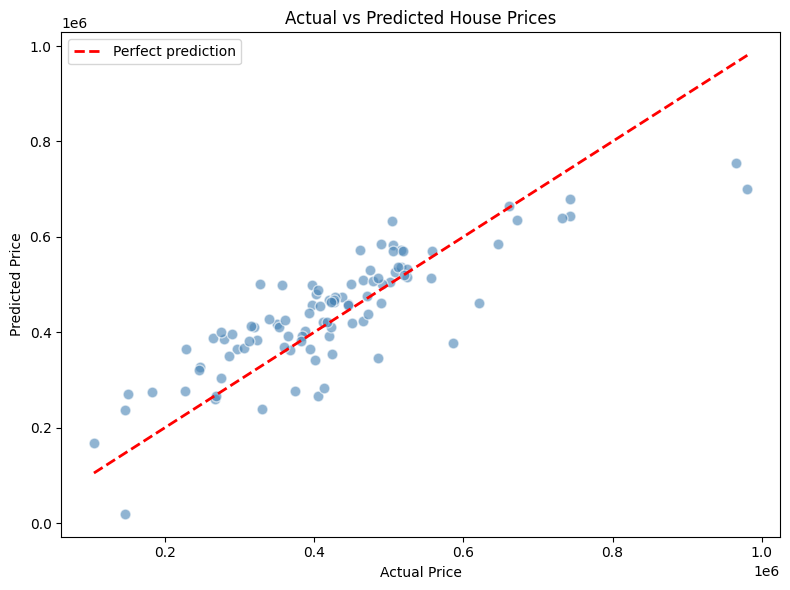

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Boston Housing
import kagglehub
from kagglehub import KaggleDatasetAdapter
df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, "schirmerchad/bostonhoustingmlnd","housing.csv")
df.head()
df.isnull().sum()
df.duplicated().sum()
df.info()
df.describe(include='all')
feat =['RM','LSTAT','PTRATIO']
fig, axes = plt.subplots(1,3,figsize=(15,5))
for i, feature in enumerate(feat):
    sns.scatterplot(data=df, x=feature, y='MEDV', ax=axes[i])
plt.tight_layout()
plt.show()
x = df.drop(columns='MEDV')
y = df['MEDV']

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)
pipe=Pipeline(steps=[('impute', SimpleImputer()),('scale', StandardScaler())])
x_train_processed = pipe.fit_transform(x_train)
x_test_processed = pipe.transform(x_test)
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train_processed, y_train)
y_pred=model.predict(x_test_processed)
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha =0.6, color='steelblue',edgecolors='white', s=60)
plt.plot([y_test.min(),y_test.max()],[y_test.min(), y_test.max()],'r--', lw=2, label='Perfect prediction')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.tight_layout()
plt.show()


In [8]:
from sklearn.metrics import mean_squared_error,r2_score
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, Lasso

seed=42
models=[
    LinearRegression(),
    DecisionTreeRegressor(criterion='absolute_error', max_depth=8, random_state=seed),
    RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=3,
    random_state=seed
),
    Ridge(alpha=1.0, random_state=seed),
    Lasso(alpha=0.1, random_state=seed),

]
from sklearn.model_selection import KFold, cross_val_score
seed=42
def base_line(models, x, y, metrics, cv=5):
    kfold = KFold(n_splits=cv, shuffle=True, random_state=seed)
    entries = []

    for model in models:
        model_name = model.__class__.__name__
        scores = cross_val_score(model, x, y, scoring=metrics, cv=kfold)

        for i, score in enumerate(scores):
            entries.append((model_name, i, score))

    cv_df = pd.DataFrame(entries, columns=['Model', 'Fold_id', 'Score'])
    mean = cv_df.groupby('Model')['Score'].mean()
    std = cv_df.groupby('Model')['Score'].std()
    base = pd.concat([mean, std], axis=1)
    base.columns = ['mean', 'std']
    base = base.sort_values(by='mean', ascending=False)
    return base

base_line(models, x_train_processed, y_train, metrics='r2', cv=5)

Best params: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10}
Best R²: 0.8393197914504998
MSE  : 3151641977.56
RMSE : 56139.49
R²   : 0.8566


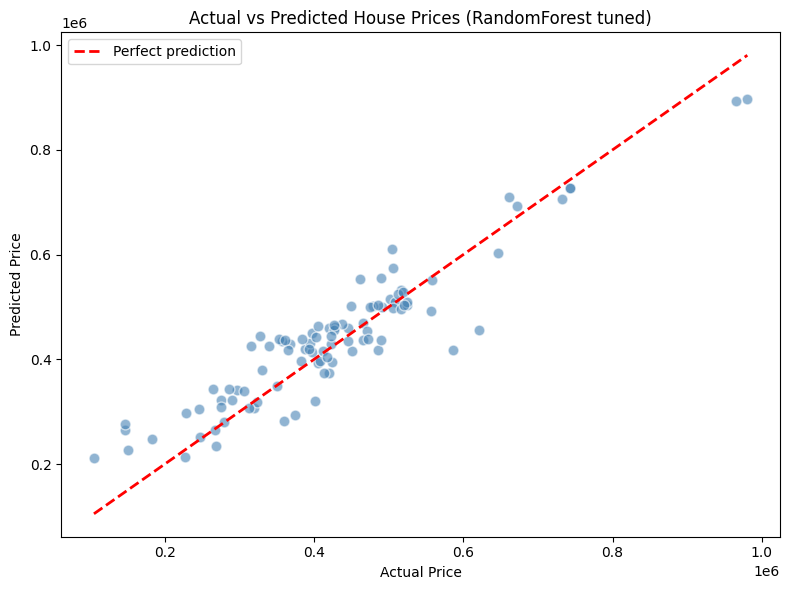

In [10]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [4, 6, 8, 10, None],
    'min_samples_leaf': [1, 2, 3, 5],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2', None]
}

rf = RandomForestRegressor(random_state=seed)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='r2',
    random_state=seed,
    n_jobs=-1
)

random_search.fit(x_train_processed, y_train)

print("Best params:", random_search.best_params_)
print("Best R²:", random_search.best_score_)
best_rf = random_search.best_estimator_
y_pred = best_rf.predict(x_test_processed)
y_pred = best_rf.predict(x_test_processed)

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

import pandas as pd
importance = pd.Series(best_rf.feature_importances_, index=x_train.columns)
importance.sort_values(ascending=False)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='steelblue', edgecolors='white', s=60)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', lw=2, label='Perfect prediction')

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices (RandomForest tuned)")
plt.legend()
plt.tight_layout()
plt.show()